<a href="https://colab.research.google.com/github/chipojaya1/ISS-Economic-Distance/blob/main/HW1_redo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prepare environment and load the data

In [4]:
# define necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# load wdi data as wdi from my github https://github.com/chipojaya1/ISS-Economic-Distance/blob/main/data/WDI_Raw_2019.xlsx
df = pd.read_excel('https://github.com/chipojaya1/ISS-Economic-Distance/blob/main/data/WDI_Raw_2019.xlsx?raw=true')

print("df type:", type(df))
print("df shape:", df.shape)
df.head()

df type: <class 'pandas.core.frame.DataFrame'>
df shape: (873, 5)


,Country Name,Country Code,Series Name,Series Code,2019 [YR2019]
0,Afghanistan,AFG,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,557.861533
1,Afghanistan,AFG,"Inflation, GDP deflator (annual %)",NY.GDP.DEFL.KD.ZG,6.52148
2,Afghanistan,AFG,Imports of goods and services (% of GDP),NE.IMP.GNFS.ZS,..
3,Afghanistan,AFG,Exports of goods and services (% of GDP),NE.EXP.GNFS.ZS,..
4,Albania,ALB,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,5072.436484


In [6]:
# 1. Clean up potential leading/trailing whitespaces in string columns
df['Series Name'] = df['Series Name'].str.strip()
display(df.head())

,Country Name,Country Code,Series Name,Series Code,2019 [YR2019]
0,Afghanistan,AFG,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,557.861533
1,Afghanistan,AFG,"Inflation, GDP deflator (annual %)",NY.GDP.DEFL.KD.ZG,6.52148
2,Afghanistan,AFG,Imports of goods and services (% of GDP),NE.IMP.GNFS.ZS,..
3,Afghanistan,AFG,Exports of goods and services (% of GDP),NE.EXP.GNFS.ZS,..
4,Albania,ALB,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,5072.436484


In [14]:
# 2. Define the mapping for Series Name renaming
name_mapping = {
    'GDP per capita (constant 2015 US$)': 'gdp_per_capita',
    'Inflation, GDP deflator (annual %)': 'inflation',
    'Imports of goods and services (% of GDP)': 'imports_pct_gdp',
    'Exports of goods and services (% of GDP)': 'exports_pct_gdp'
}

# Filter to keep only the series we are interested in and map their names
df_filtered = df[df['Series Name'].isin(name_mapping.keys())].copy()
df_filtered['Series Name'] = df_filtered['Series Name'].map(name_mapping)
display(df_filtered.head())

,Country Name,Country Code,Series Name,Series Code,2019 [YR2019]
0,Afghanistan,AFG,gdp_per_capita,NY.GDP.PCAP.KD,557.861533
1,Afghanistan,AFG,inflation,NY.GDP.DEFL.KD.ZG,6.52148
2,Afghanistan,AFG,imports_pct_gdp,NE.IMP.GNFS.ZS,..
3,Afghanistan,AFG,exports_pct_gdp,NE.EXP.GNFS.ZS,..
4,Albania,ALB,gdp_per_capita,NY.GDP.PCAP.KD,5072.436484


In [15]:
# 3. Clean the value column: replace '..' with NaN and convert to float
val_col = '2019 [YR2019]'
df_filtered[val_col] = df_filtered[val_col].replace('..', np.nan)
df_filtered[val_col] = pd.to_numeric(df_filtered[val_col], errors='coerce')
display(df_filtered.head())

/tmp/ipykernel_11322/3241800311.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_filtered[val_col] = df_filtered[val_col].replace('..', np.nan)


,Country Name,Country Code,Series Name,Series Code,2019 [YR2019]
0,Afghanistan,AFG,gdp_per_capita,NY.GDP.PCAP.KD,557.861533
1,Afghanistan,AFG,inflation,NY.GDP.DEFL.KD.ZG,6.521480
2,Afghanistan,AFG,imports_pct_gdp,NE.IMP.GNFS.ZS,NaN
3,Afghanistan,AFG,exports_pct_gdp,NE.EXP.GNFS.ZS,NaN
4,Albania,ALB,gdp_per_capita,NY.GDP.PCAP.KD,5072.436484


In [16]:
# 4. Pivot from long to wide (short) format
df_wide = df_filtered.pivot(index=['Country Name', 'Country Code'], columns='Series Name', values=val_col).reset_index()

# Reset column index name
df_wide.columns.name = None

# Display the cleaned and reshaped DataFrame
print("df_wide shape:", df_wide.shape)
display(df_wide.head())

df_wide shape: (217, 6)


,Country Name,Country Code,exports_pct_gdp,gdp_per_capita,imports_pct_gdp,inflation
0,Afghanistan,AFG,NaN,557.861533,NaN,6.521480
1,Albania,ALB,30.936122,5072.436484,44.446006,1.000633
2,Algeria,DZA,20.407942,4672.664087,26.098901,0.882993
3,American Samoa,ASM,61.669243,12524.016025,94.899536,1.748289
4,Andorra,AND,NaN,39346.275036,NaN,1.374754


In [17]:
# mask data as wdi_df
wdi_df = df_wide
wdi_df.head()

,Country Name,Country Code,exports_pct_gdp,gdp_per_capita,imports_pct_gdp,inflation
0,Afghanistan,AFG,NaN,557.861533,NaN,6.521480
1,Albania,ALB,30.936122,5072.436484,44.446006,1.000633
2,Algeria,DZA,20.407942,4672.664087,26.098901,0.882993
3,American Samoa,ASM,61.669243,12524.016025,94.899536,1.748289
4,Andorra,AND,NaN,39346.275036,NaN,1.374754


# Exploratory Data Analysis

In [20]:
wdi_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Country Name     217 non-null    object 
 1   Country Code     217 non-null    object 
 2   exports_pct_gdp  183 non-null    float64
 3   gdp_per_capita   208 non-null    float64
 4   imports_pct_gdp  183 non-null    float64
 5   inflation        209 non-null    float64
dtypes: float64(4), object(2)
memory usage: 10.3+ KB


In [19]:
# Summary statistics
summary_stats = wdi_df.describe()
print("Summary Statistics:")
display(summary_stats)

Summary Statistics:


,exports_pct_gdp,gdp_per_capita,imports_pct_gdp,inflation
count,183.000000,208.000000,183.000000,209.000000
mean,43.059452,17544.183111,48.085723,110.387032
std,31.529306,24664.928816,28.529602,1515.376731
min,7.779936,270.411006,10.607517,-4.603271
25%,22.282452,2423.171056,28.704516,0.848015
50%,36.400882,6533.112217,41.469590,2.375860
75%,52.400877,21751.331731,58.928664,4.175673
max,206.580146,185582.668516,176.092206,21909.342668


Text(0.5, 0, 'GDP per Capita')

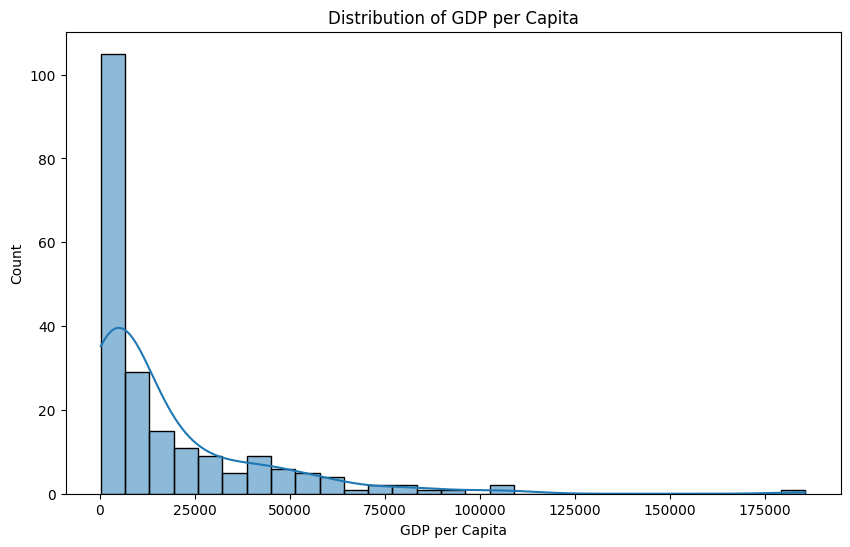

In [21]:
# Visualize distribution of GDP per capita
plt.figure(figsize=(10, 6))
sns.histplot(wdi_df['gdp_per_capita'].dropna(), kde=True)
plt.title('Distribution of GDP per Capita')
plt.xlabel('GDP per Capita')

Text(0, 0.5, 'Inflation')

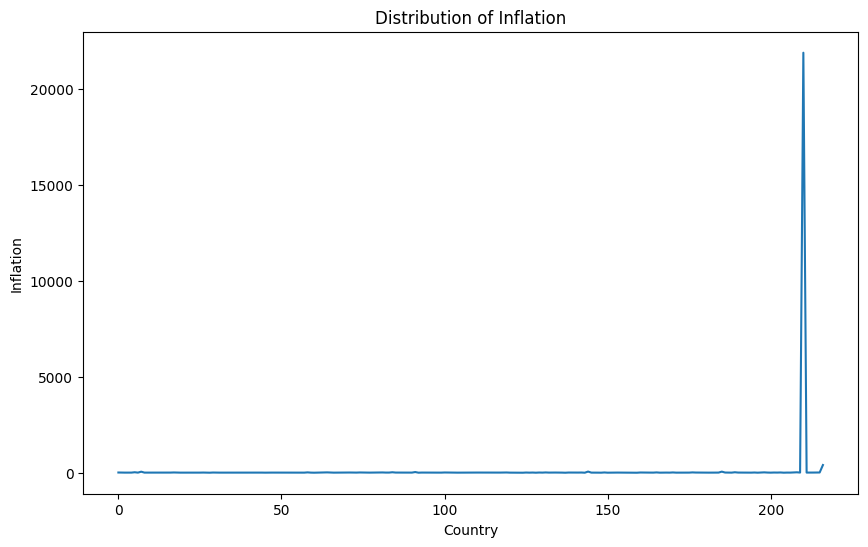

In [28]:
# Visualize distribution of Inflation
plt.figure(figsize=(10, 6))
sns.lineplot(x=wdi_df.index, y='inflation', data=wdi_df)
plt.title('Distribution of Inflation')
plt.xlabel('Country')
plt.ylabel('Inflation')

Text(0.5, 0, 'Imports')

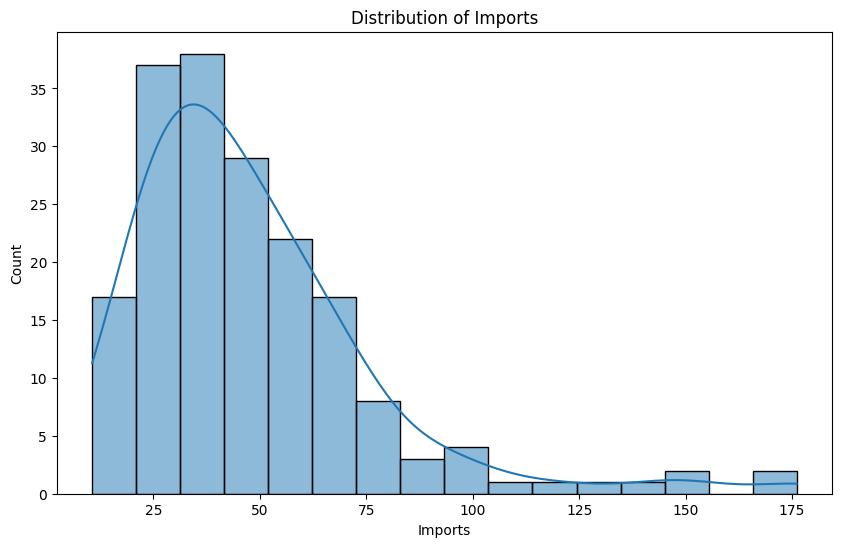

In [23]:
# Visualize distribution of Imports
plt.figure(figsize=(10, 6))
sns.histplot(wdi_df['imports_pct_gdp'].dropna(), kde=True)
plt.title('Distribution of Imports')
plt.xlabel('Imports')

Text(0.5, 0, 'Exports')

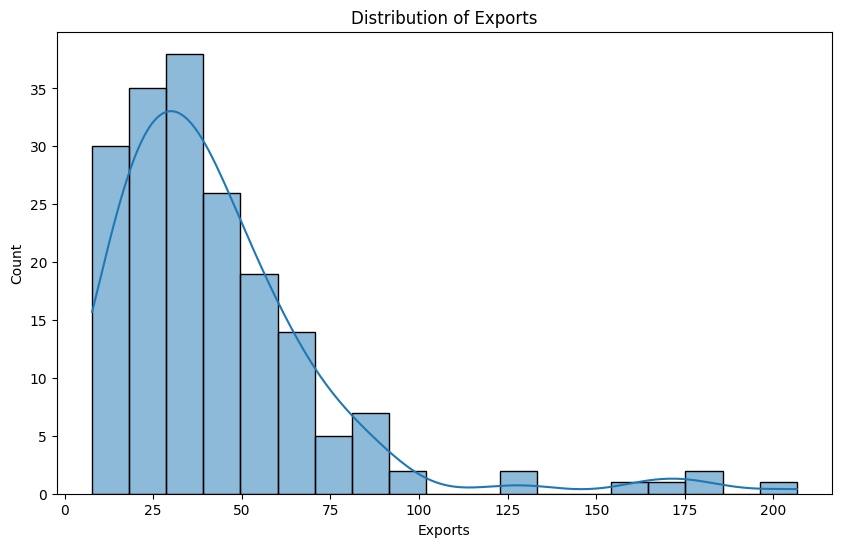

In [24]:
# Visualize distribution of Exports
plt.figure(figsize=(10, 6))
sns.histplot(wdi_df['exports_pct_gdp'].dropna(), kde=True)
plt.title('Distribution of Exports')
plt.xlabel('Exports')

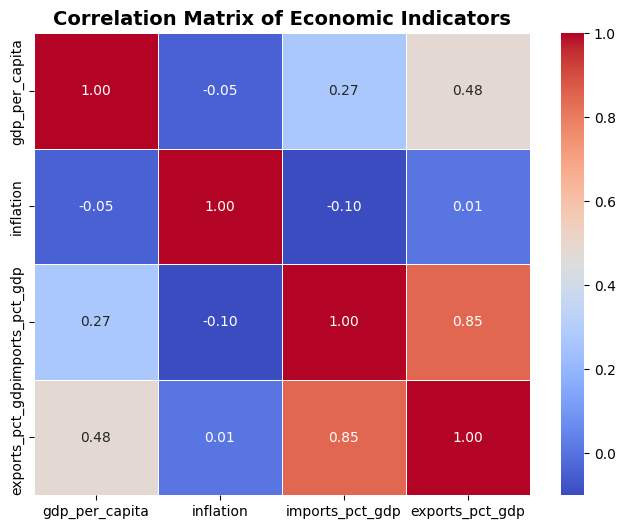

In [27]:
# Create a correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(wdi_df[cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Economic Indicators', fontsize=14, fontweight='bold')
plt.show()